# Transformer. Seminar 1. Attention

Семинар для магистратуры: разбираем механизм attention не как черный ящик, а как последовательность понятных тензорных операций.

Что будет:

- ручная реализация `softmax` и scaled dot-product attention;
- визуализация attention-карт;
- padding mask и causal mask;
- одно- и multi-head self-attention через `torch.nn.Parameter`;
- маленькая обучаемая задача на CPU, чтобы проверить, что механизм работает;
- практические вопросы и мини-эксперименты по ходу.

Задания устроены так: ячейка, которую надо поправить или дописать, и сразу под ней решение. Если прогнать ноутбук целиком, решение перезаписывает функцию.


## 0. Зависимости

pytorch cpu + matplotlib

In [1]:
import math
import os
import random
import time
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path(".mplconfig").resolve()))
os.environ.setdefault("HF_HOME", str(Path(".hf_cache").resolve()))

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import matplotlib.pyplot as plt
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        "Не хватает зависимости. Для семинара установите: pip install torch matplotlib"
    ) from e


# Детерминизм и щадящий режим для слабых CPU.
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(2, os.cpu_count() or 1))

device = torch.device("cpu")
print("torch:", torch.__version__)
print("device:", device)
print("threads:", torch.get_num_threads())
print("MPLCONFIGDIR:", os.environ["MPLCONFIGDIR"])
print("HF_HOME:", os.environ["HF_HOME"])

torch: 2.8.0
device: cpu
threads: 2
MPLCONFIGDIR: /Users/fedorkurushin/Documents/ChatGPT/seminars_mephi/transformers/transformer_attention_pytorch/.mplconfig
HF_HOME: /Users/fedorkurushin/Documents/ChatGPT/seminars_mephi/transformers/transformer_attention_pytorch/.hf_cache


## 1. Интуиция attention

Attention отвечает на вопрос:

> Для каждого токена-запроса, на какие токены-контекст ему смотреть и с какими весами?

Внутри у каждого токена появляются три вектора:

- `q` / query: что я ищу;
- `k` / key: по каким признакам меня можно найти;
- `v` / value: какую информацию я отдам, если на меня посмотрят.

Формула scaled dot-product attention:

$$
\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

Размерности для batch-first представления:

- `Q`: `[batch, n_queries, d_k]`
- `K`: `[batch, n_keys, d_k]`
- `V`: `[batch, n_keys, d_v]`
- `scores = Q @ K.T`: `[batch, n_queries, n_keys]`
- `weights`: `[batch, n_queries, n_keys]`
- `output`: `[batch, n_queries, d_v]`

https://arxiv.org/html/1706.03762

In [2]:
tokens = ["I", "love", "linear", "algebra"]
n = len(tokens)
d_k = 3
d_v = 2

Q = torch.tensor([[
    [1.0, 0.0, 0.0],   # I
    [0.0, 1.0, 0.0],   # love
    [0.7, 0.7, 0.0],   # linear
    [0.0, 0.2, 1.0],   # algebra
]])
K = torch.tensor([[
    [1.0, 0.1, 0.0],
    [0.0, 1.0, 0.2],
    [0.8, 0.8, 0.0],
    [0.0, 0.1, 1.0],
]])
V = torch.tensor([[
    [1.0, 0.0],
    [0.0, 1.0],
    [0.7, 0.7],
    [0.2, 1.2],
]])

print("Q:", Q.shape)
print("K:", K.shape)
print("V:", V.shape)

Q: torch.Size([1, 4, 3])
K: torch.Size([1, 4, 3])
V: torch.Size([1, 4, 2])


## 2. Softmax руками

Softmax превращает произвольные scores в распределение вероятностей:

$$
\mathrm{softmax}(x_i) = \frac{e^{x_i}}{\sum_j e^{x_j}}
$$

### Задание. Найди ошибку

На больших числах функция ниже дает `nan`. Найди причину.


In [ ]:
def stable_softmax(x, dim=-1):
    exp_x = torch.exp(x)
    return exp_x / exp_x.sum(dim=dim, keepdim=True)


toy_scores = torch.tensor([[1.0, 2.0, 3.0], [10.0, 0.0, -10.0]])
big_scores = toy_scores * 100
print(stable_softmax(big_scores))


### Решение

Перед `exp` вычитаем максимум по той оси, где нормируем. На обычных числах результат тот же, переполнения нет.


In [ ]:
def stable_softmax(x, dim=-1):
    x_shifted = x - x.max(dim=dim, keepdim=True).values
    exp_x = torch.exp(x_shifted)
    return exp_x / exp_x.sum(dim=dim, keepdim=True)


def naive_softmax(x, dim=-1):
    exp_x = torch.exp(x)
    return exp_x / exp_x.sum(dim=dim, keepdim=True)


toy_scores = torch.tensor([[1.0, 2.0, 3.0], [10.0, 0.0, -10.0]])
print(stable_softmax(toy_scores, dim=-1))
print("row sums:", stable_softmax(toy_scores, dim=-1).sum(dim=-1))
print("matches torch:", torch.allclose(stable_softmax(toy_scores), F.softmax(toy_scores, dim=-1)))

big_scores = toy_scores * 100
print("stable:")
print(stable_softmax(big_scores))
print("naive:")
print(naive_softmax(big_scores))


## 3. Scaled dot-product attention

### Задание. Допиши

Собери `scaled_dot_product_attention`:

1. scores: `Q @ K.T`, деленные на `sqrt(d_k)`;
2. если есть маска, позиции с `mask=False` замени на очень маленькое число до softmax;
3. softmax по ключам;
4. взвешенная сумма `V`.


In [ ]:
def scaled_dot_product_attention(Q, K, V, mask=None, return_scores=False):
    # Q: [batch, n_queries, d_k]
    # K: [batch, n_keys, d_k]
    # V: [batch, n_keys, d_v]
    # mask: True значит «смотреть можно»
    d_k = Q.size(-1)
    scores = ...
    if mask is not None:
        scores = ...
    weights = ...
    output = ...

    if return_scores:
        return output, weights, scores
    return output, weights


### Решение


In [ ]:
def scaled_dot_product_attention(Q, K, V, mask=None, return_scores=False):
    # Q: [batch, n_queries, d_k]
    # K: [batch, n_keys, d_k]
    # V: [batch, n_keys, d_v]
    # mask: broadcastable to [batch, n_queries, n_keys], True means "можно смотреть"
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)

    weights = stable_softmax(scores, dim=-1)
    output = weights @ V

    if return_scores:
        return output, weights, scores
    return output, weights


output, weights, scores = scaled_dot_product_attention(Q, K, V, return_scores=True)
print("scores:", scores.shape)
print("weights:", weights.shape)
print("output:", output.shape)
print("\nattention weights:")
print(weights[0].round(decimals=3))


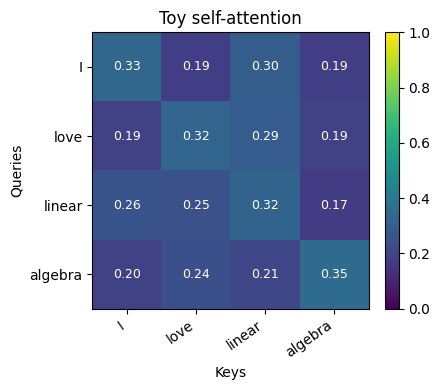

In [6]:
def plot_attention(weights, x_labels=None, y_labels=None, title="Attention weights", ax=None):
    if weights.dim() == 3:
        weights = weights[0]

    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4))

    im = ax.imshow(weights.detach().cpu(), cmap="viridis", vmin=0.0, vmax=1.0)
    ax.set_title(title)
    ax.set_xlabel("Keys")
    ax.set_ylabel("Queries")

    if x_labels is not None:
        ax.set_xticks(range(len(x_labels)))
        ax.set_xticklabels(x_labels, rotation=35, ha="right")
    if y_labels is not None:
        ax.set_yticks(range(len(y_labels)))
        ax.set_yticklabels(y_labels)

    for i in range(weights.size(0)):
        for j in range(weights.size(1)):
            ax.text(j, i, f"{weights[i, j]:.2f}", ha="center", va="center", color="white", fontsize=9)

    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return ax


plot_attention(weights, tokens, tokens, "Toy self-attention")
plt.tight_layout()
plt.show()

### Практика 2

Поменяйте `Q` и `K` в первой игрушечной матрице так, чтобы:

- токен `linear` сильнее всего смотрел на `algebra`;
- токен `love` почти равномерно смотрел на все токены.

Подсказка: attention зависит от скалярного произведения query текущего токена с key каждого токена.

## 4. Зачем делить на `sqrt(d_k)`

Если `d_k` большой, скалярные произведения становятся крупнее по масштабу. Softmax получает большие значения и становится слишком "острым": почти вся вероятность уходит в один токен, градиенты могут стать менее полезными.

Проверим это на случайных векторах.

In [7]:
def attention_entropy(weights, eps=1e-12):
    return -(weights * (weights + eps).log()).sum(dim=-1).mean()


for dim in [4, 16, 64, 256]:
    q = torch.randn(1, 8, dim)
    k = torch.randn(1, 8, dim)
    raw_scores = q @ k.transpose(-2, -1)
    scaled_scores = raw_scores / math.sqrt(dim)

    raw_w = stable_softmax(raw_scores, dim=-1)
    scaled_w = stable_softmax(scaled_scores, dim=-1)

    print(
        f"d_k={dim:3d} | "
        f"entropy без scale={attention_entropy(raw_w):.3f} | "
        f"entropy со scale={attention_entropy(scaled_w):.3f}"
    )

d_k=  4 | entropy без scale=1.185 | entropy со scale=1.741
d_k= 16 | entropy без scale=0.698 | entropy со scale=1.815
d_k= 64 | entropy без scale=0.127 | entropy со scale=1.745
d_k=256 | entropy без scale=0.097 | entropy со scale=1.598


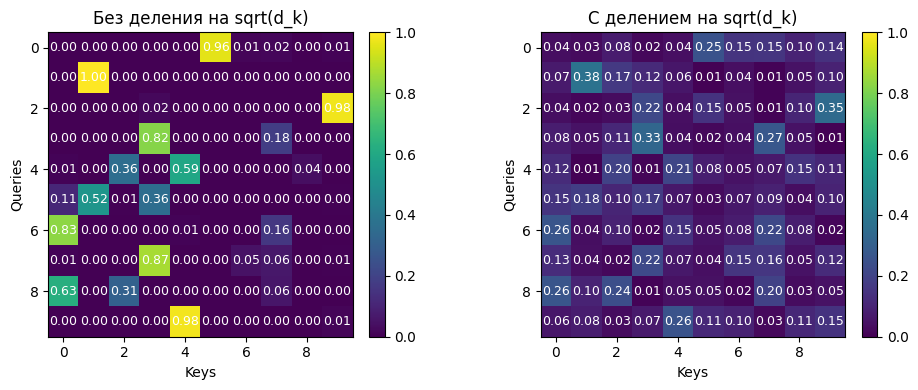

In [8]:
dim = 64
q = torch.randn(1, 10, dim)
k = torch.randn(1, 10, dim)
v = torch.randn(1, 10, 4)

scores_no_scale = q @ k.transpose(-2, -1)
weights_no_scale = stable_softmax(scores_no_scale, dim=-1)

_, weights_scaled = scaled_dot_product_attention(q, k, v)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_attention(weights_no_scale, title="Без деления на sqrt(d_k)", ax=axes[0])
plot_attention(weights_scaled, title="С делением на sqrt(d_k)", ax=axes[1])
plt.tight_layout()
plt.show()

## 5. Маски: padding и causal

Маска нужна, чтобы запретить attention смотреть на некоторые позиции.

Два главных типа:

- `padding mask`: не смотреть на `<pad>` токены;
- `causal mask`: в decoder-only LM не смотреть в будущее.

В реализации выше `mask=True` означает "смотреть можно", `mask=False` означает "запрещено".

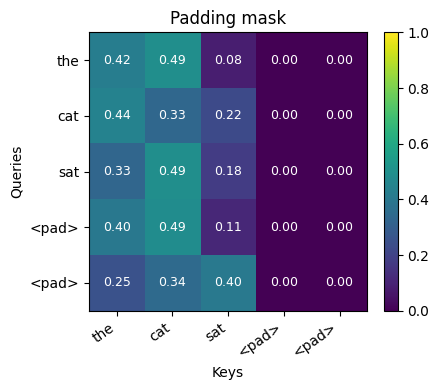

Сумма весов по ключам: tensor([[1., 1., 1., 1., 1.]])


In [9]:
sentence = ["the", "cat", "sat", "<pad>", "<pad>"]
seq_len = len(sentence)

padding_mask = torch.tensor([[True, True, True, False, False]])  # [batch, n_keys]
padding_mask = padding_mask[:, None, :]                         # [batch, 1, n_keys]
padding_mask = padding_mask.expand(1, seq_len, seq_len)          # [batch, n_queries, n_keys]

Q2 = torch.randn(1, seq_len, 4)
K2 = torch.randn(1, seq_len, 4)
V2 = torch.randn(1, seq_len, 3)

_, weights_padding = scaled_dot_product_attention(Q2, K2, V2, mask=padding_mask)

plot_attention(weights_padding, sentence, sentence, "Padding mask")
plt.tight_layout()
plt.show()
print("Сумма весов по ключам:", weights_padding.sum(dim=-1).round(decimals=3))

### Задание. Найди ошибку

Causal mask в decoder-only LM запрещает смотреть в будущее. `True` значит «смотреть можно». Ниже маска разрешает не те позиции.


In [ ]:
def make_causal_mask(seq_len, batch_size=1):
    allowed = torch.triu(torch.ones(seq_len, seq_len, dtype=torch.bool))
    return allowed[None, :, :].expand(batch_size, seq_len, seq_len)


causal_mask = make_causal_mask(seq_len)
print(causal_mask[0].int())
_, weights_causal = scaled_dot_product_attention(Q2, K2, V2, mask=causal_mask)

plot_attention(weights_causal, sentence, sentence, "Causal mask — задание")
plt.tight_layout()
plt.show()


### Решение

Нужен нижний треугольник: позиция смотрит на себя и на прошлое.


In [ ]:
def make_causal_mask(seq_len, batch_size=1):
    allowed = torch.tril(torch.ones(seq_len, seq_len, dtype=torch.bool))
    return allowed[None, :, :].expand(batch_size, seq_len, seq_len)


causal_mask = make_causal_mask(seq_len)
print(causal_mask[0].int())
_, weights_causal = scaled_dot_product_attention(Q2, K2, V2, mask=causal_mask)

plot_attention(weights_causal, sentence, sentence, "Causal mask")
plt.tight_layout()
plt.show()


### Задание. Допиши

Собери маску, которая сразу запрещает будущее и `<pad>`. Сейчас выключено только будущее: вес на `<pad>` не ноль.


In [ ]:
combined_mask = causal_mask
_, weights_combined = scaled_dot_product_attention(Q2, K2, V2, mask=combined_mask)
print("вес на <pad>:", weights_combined[0, :, 3:].sum().round(decimals=3))

plot_attention(weights_combined, sentence, sentence, "Задание: causal + padding")
plt.tight_layout()
plt.show()


### Решение


In [ ]:
combined_mask = causal_mask & padding_mask
_, weights_combined = scaled_dot_product_attention(Q2, K2, V2, mask=combined_mask)
print("вес на <pad>:", weights_combined[0, :, 3:].sum().round(decimals=3))

plot_attention(weights_combined, sentence, sentence, "Causal + padding mask")
plt.tight_layout()
plt.show()


## 6. Self-attention слой с обучаемыми весами

До этого `Q`, `K`, `V` были даны руками. В трансформере они получаются линейными проекциями входных эмбеддингов:

$$
Q=XW_Q,\quad K=XW_K,\quad V=XW_V
$$

Ниже слой без `nn.MultiheadAttention`: параметры создаем сами через `nn.Parameter`, а attention считаем нашей функцией.

In [12]:
class SingleHeadSelfAttention(nn.Module):
    def __init__(self, d_model, d_head):
        super().__init__()
        self.d_model = d_model
        self.d_head = d_head

        scale = 1.0 / math.sqrt(d_model)
        self.W_q = nn.Parameter(torch.randn(d_model, d_head) * scale)
        self.W_k = nn.Parameter(torch.randn(d_model, d_head) * scale)
        self.W_v = nn.Parameter(torch.randn(d_model, d_head) * scale)
        self.W_o = nn.Parameter(torch.randn(d_head, d_model) * (1.0 / math.sqrt(d_head)))

    def forward(self, x, mask=None, need_weights=False):
        Q = x @ self.W_q
        K = x @ self.W_k
        V = x @ self.W_v

        out, weights = scaled_dot_product_attention(Q, K, V, mask=mask)
        out = out @ self.W_o

        if need_weights:
            return out, weights
        return out


x = torch.randn(2, 5, 16)
layer = SingleHeadSelfAttention(d_model=16, d_head=8)
y, attn = layer(x, need_weights=True)
print("x:", x.shape)
print("y:", y.shape)
print("attn:", attn.shape)

x: torch.Size([2, 5, 16])
y: torch.Size([2, 5, 16])
attn: torch.Size([2, 5, 5])


## 7. Multi-head attention с нуля

Одна голова смотрит на один тип отношений. Несколько голов позволяют параллельно смотреть на разные паттерны:

- синтаксическая близость;
- совпадение сущностей;
- локальный контекст;
- дальняя зависимость.

В коде:

1. делаем общие проекции `W_q`, `W_k`, `W_v`;
2. режем последнюю размерность на `n_heads`;
3. считаем attention независимо по головам;
4. склеиваем головы обратно;
5. применяем output projection.

In [13]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0, "d_model должен делиться на n_heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads

        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.W_o = nn.Linear(d_model, d_model, bias=False)

    def split_heads(self, x):
        batch, seq_len, d_model = x.shape
        x = x.view(batch, seq_len, self.n_heads, self.d_head)
        return x.transpose(1, 2)  # [batch, heads, seq_len, d_head]

    def merge_heads(self, x):
        batch, heads, seq_len, d_head = x.shape
        x = x.transpose(1, 2).contiguous()
        return x.view(batch, seq_len, heads * d_head)

    def forward(self, x, mask=None, need_weights=False):
        Q = self.split_heads(self.W_q(x))
        K = self.split_heads(self.W_k(x))
        V = self.split_heads(self.W_v(x))

        if mask is not None:
            mask = mask[:, None, :, :]  # [batch, 1, seq, seq], broadcast over heads

        out, weights = scaled_dot_product_attention(Q, K, V, mask=mask)
        out = self.merge_heads(out)
        out = self.W_o(out)

        if need_weights:
            return out, weights
        return out


mha = MultiHeadSelfAttention(d_model=16, n_heads=4)
y, w = mha(x, need_weights=True)
print("output:", y.shape)
print("weights:", w.shape)  # [batch, heads, queries, keys]

output: torch.Size([2, 5, 16])
weights: torch.Size([2, 4, 5, 5])


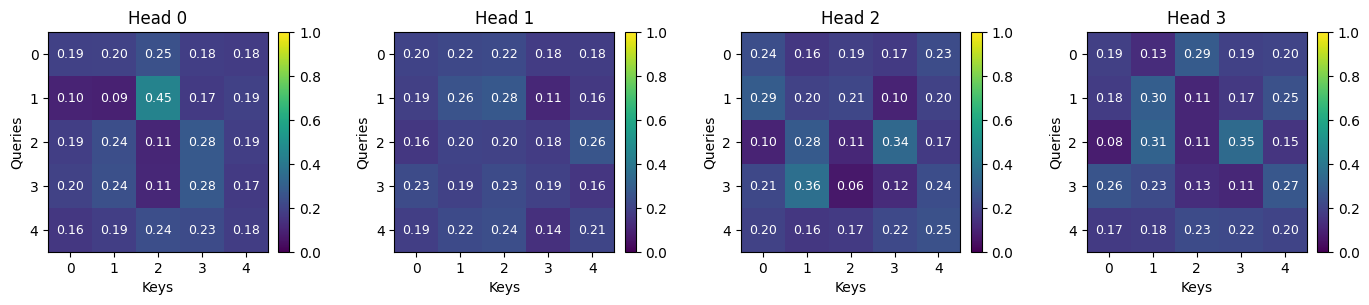

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for head in range(4):
    plot_attention(w[0, head], title=f"Head {head}", ax=axes[head])
plt.tight_layout()
plt.show()

### Практика 4

1. Поменяйте `n_heads` на `1`, `2`, `8`.
2. Посмотрите, как меняется форма `weights`.
3. Ответьте: почему `d_model % n_heads == 0`?
4. Что станет вычислительно дороже при росте длины последовательности: `seq_len` или `d_model`?

## 8. Мини-трансформерный блок

Полный transformer block обычно содержит:

- self-attention;
- residual connection;
- layer norm;
- feed-forward network;
- еще один residual;
- еще один layer norm.

Для семинара соберем маленькую версию. Она достаточно настоящая, но очень легкая.

In [15]:
class TinyTransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff):
        super().__init__()
        self.attn = MultiHeadSelfAttention(d_model, n_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model),
        )
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, mask=None, need_weights=False):
        if need_weights:
            attn_out, weights = self.attn(x, mask=mask, need_weights=True)
        else:
            attn_out = self.attn(x, mask=mask)
            weights = None

        x = self.norm1(x + attn_out)
        x = self.norm2(x + self.ff(x))

        if need_weights:
            return x, weights
        return x

## 9. Маленькая задача: предсказать следующий токен

Сделаем синтетический язык без датасета:

Последовательность идет по модулю словаря:

`[3, 4, 5, 6, 7] -> target [4, 5, 6, 7, 8]`

Модель должна научиться правилу "следующий токен = текущий + 1 mod vocab_size".

Это не языковая модель в настоящем смысле, но хороший smoke test:

- attention и маска работают;
- backward проходит;
- loss падает;
- все обучается на CPU за секунды.

In [16]:
def make_batch(batch_size=32, seq_len=8, vocab_size=20):
    starts = torch.randint(0, vocab_size, (batch_size, 1))
    steps = torch.arange(seq_len).unsqueeze(0)
    x = (starts + steps) % vocab_size
    y = (x + 1) % vocab_size
    return x.long(), y.long()


class TinyCausalLM(nn.Module):
    def __init__(self, vocab_size=20, d_model=32, n_heads=4, d_ff=64, max_len=32):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.block = TinyTransformerBlock(d_model, n_heads, d_ff)
        self.lm_head = nn.Linear(d_model, vocab_size)

    def forward(self, idx, need_weights=False):
        batch, seq_len = idx.shape
        pos = torch.arange(seq_len, device=idx.device).unsqueeze(0).expand(batch, seq_len)
        x = self.token_emb(idx) + self.pos_emb(pos)
        mask = make_causal_mask(seq_len, batch_size=batch).to(idx.device)

        if need_weights:
            x, weights = self.block(x, mask=mask, need_weights=True)
            return self.lm_head(x), weights

        x = self.block(x, mask=mask)
        return self.lm_head(x)


model = TinyCausalLM(vocab_size=20, d_model=32, n_heads=4, d_ff=64, max_len=16)
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 10228


In [17]:
def train_tiny_lm(model, steps=120, batch_size=64, seq_len=8, vocab_size=20, lr=3e-3):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    losses = []
    t0 = time.time()

    model.train()
    for step in range(1, steps + 1):
        x, y = make_batch(batch_size=batch_size, seq_len=seq_len, vocab_size=vocab_size)
        logits = model(x)
        loss = F.cross_entropy(logits.view(-1, vocab_size), y.view(-1))

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        if step == 1 or step % 20 == 0:
            print(f"step {step:03d} | loss {loss.item():.4f}")

    print(f"elapsed: {time.time() - t0:.1f}s")
    return losses


losses = train_tiny_lm(model)

step 001 | loss 3.1298
step 020 | loss 1.0455
step 040 | loss 0.1959
step 060 | loss 0.0661
step 080 | loss 0.0340
step 100 | loss 0.0226


step 120 | loss 0.0168
elapsed: 0.2s


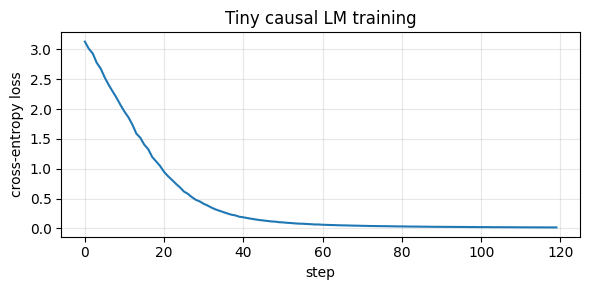

In [18]:
plt.figure(figsize=(6, 3))
plt.plot(losses)
plt.xlabel("step")
plt.ylabel("cross-entropy loss")
plt.title("Tiny causal LM training")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

input:  [12, 13, 14, 15, 16, 17, 18, 19]
target: [13, 14, 15, 16, 17, 18, 19, 0]
pred:   [13, 14, 15, 16, 17, 18, 19, 0]


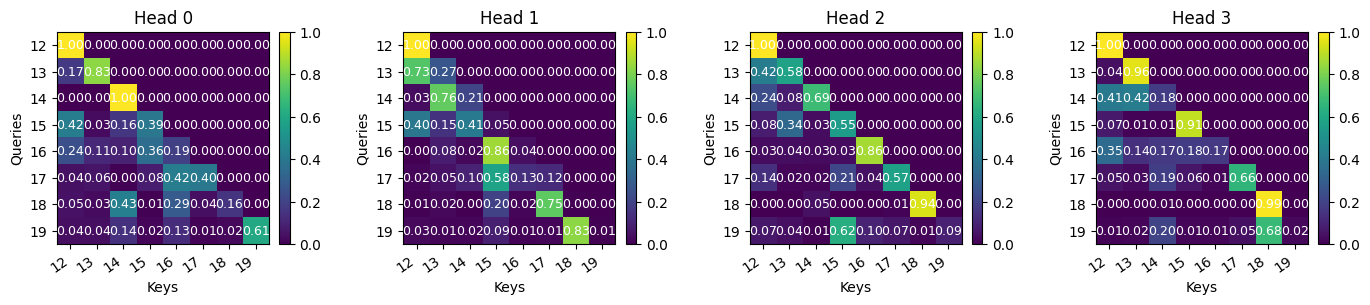

In [19]:
model.eval()
x, y = make_batch(batch_size=1, seq_len=8, vocab_size=20)
with torch.no_grad():
    logits, weights = model(x, need_weights=True)
    pred = logits.argmax(dim=-1)

print("input: ", x[0].tolist())
print("target:", y[0].tolist())
print("pred:  ", pred[0].tolist())

fig, axes = plt.subplots(1, weights.size(1), figsize=(14, 3))
labels = [str(i) for i in x[0].tolist()]
for head in range(weights.size(1)):
    plot_attention(weights[0, head], labels, labels, title=f"Head {head}", ax=axes[head])
plt.tight_layout()
plt.show()

### Практика 5

Проведите три мини-эксперимента:

1. Уберите causal mask в `TinyCausalLM.forward`. Что произойдет с задачей и почему это "читерство"?
2. Уменьшите `d_model` до `8`. Хватает ли емкости?
3. Увеличьте `seq_len` до `16`. Насколько медленнее стало обучение?

Важно: длина последовательности особенно дорогая, потому что attention matrix имеет размер `seq_len x seq_len`.

## 10. Optional: TinyBERT на CPU

Основной семинар выше не требует HuggingFace и интернета. Но в конце можно показать, что маленькая BERT-подобная модель действительно запускается на CPU.

Этот блок опциональный:

- нужен пакет `transformers`;
- первая загрузка модели требует интернет;
- если интернет плохой или модель не закэширована, просто пропускаем блок;
- для слабых ноутбуков используем короткий текст и `torch.no_grad()`.

В примере ниже берем очень маленькую BERT-модель `prajjwal1/bert-tiny`. Это не ровно "TinyBERT" из статьи, но для учебной демонстрации внимания и hidden states она удобнее: маленькая, быстрая и обычно без боли запускается на CPU.

In [20]:
RUN_TINY_BERT = False  # Поставьте True, если хотите запустить optional-блок.

if RUN_TINY_BERT:
    try:
        from transformers import AutoModel, AutoTokenizer

        model_name = "prajjwal1/bert-tiny"
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        tiny_bert = AutoModel.from_pretrained(model_name, output_attentions=True)
        tiny_bert.eval()

        text = "attention lets tokens look at other tokens"
        encoded = tokenizer(text, return_tensors="pt")

        with torch.no_grad():
            out = tiny_bert(**encoded)

        print("tokens:", tokenizer.convert_ids_to_tokens(encoded["input_ids"][0]))
        print("last_hidden_state:", tuple(out.last_hidden_state.shape))
        print("layers with attentions:", len(out.attentions))
        print("one attention tensor:", tuple(out.attentions[0].shape))
    except ModuleNotFoundError:
        print("Пакет transformers не установлен. Для optional-блока: pip install transformers")
    except Exception as e:
        print("TinyBERT-блок не запустился. Скорее всего, нет интернета или модель не закэширована.")
        print(type(e).__name__ + ":", e)
else:
    print("Optional TinyBERT-блок выключен. Поставьте RUN_TINY_BERT = True, чтобы запустить.")

Optional TinyBERT-блок выключен. Поставьте RUN_TINY_BERT = True, чтобы запустить.


In [21]:
if RUN_TINY_BERT and "out" in globals():
    tokens_for_plot = tokenizer.convert_ids_to_tokens(encoded["input_ids"][0])
    first_layer_first_head = out.attentions[0][0, 0]

    plt.figure(figsize=(7, 5))
    plot_attention(
        first_layer_first_head,
        x_labels=tokens_for_plot,
        y_labels=tokens_for_plot,
        title="BERT-tiny: layer 0, head 0",
    )
    plt.tight_layout()
    plt.show()
else:
    print("Нет attention-карты TinyBERT: optional-блок выключен или не запустился.")

Нет attention-карты TinyBERT: optional-блок выключен или не запустился.


### Практика 6

Если optional-блок запустился:

1. Поменяйте текст на русский или смешанный русско-английский.
2. Посмотрите, как tokenizer режет слова на subword-токены.
3. Сравните attention-карты разных голов и слоев.

Обсуждение: почему красивые attention-карты не всегда являются надежным объяснением решения модели?

## 11. Контрольные вопросы

1. Почему attention weights суммируются в `1` по оси ключей, а не по оси query?
2. Что именно маскируется: `Q`, `K`, `V`, scores или output?
3. Почему без `sqrt(d_k)` softmax становится слишком острым?
4. Чем self-attention отличается от cross-attention?
5. Почему multi-head attention не просто "увеличивает размерность", а меняет представление отношений?
6. Где возникает квадратичная сложность по длине последовательности?

## 12. Короткий конспект

- Attention строит для каждого query распределение по keys.
- Scores считаются как `Q @ K.T`.
- Деление на `sqrt(d_k)` стабилизирует масштаб scores.
- Softmax превращает scores в веса.
- Output - это взвешенная сумма `V`.
- Маска применяется к scores перед softmax.
- Multi-head attention делает несколько независимых attention-карт и склеивает результат.
- Главная вычислительная боль vanilla attention - матрица `[seq_len, seq_len]`.